In [1]:
from pathlib import Path
import numpy as np
import sys

# Notebook'un çalışma klasörü
CURRENT_DIR = Path.cwd()

# notebooks klasöründeysek bir üst klasöre çık
if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Python'un modül arama yoluna ekle
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loader import load_dataset

df = load_dataset()

display(df.head())
print("Veri boyutu:", df.shape)

,image,MEL,NV,BCC,AKIEC,BKL,DF,VASC,label,image_path,mask_path
0,ISIC_0024306,0.0,1.0,0.0,0.0,0.0,0.0,0.0,NV,C:\Users\Deniz TOZAN\OneDrive - Analythinx Bil...,C:\Users\Deniz TOZAN\OneDrive - Analythinx Bil...
1,ISIC_0024307,0.0,1.0,0.0,0.0,0.0,0.0,0.0,NV,C:\Users\Deniz TOZAN\OneDrive - Analythinx Bil...,C:\Users\Deniz TOZAN\OneDrive - Analythinx Bil...
2,ISIC_0024308,0.0,1.0,0.0,0.0,0.0,0.0,0.0,NV,C:\Users\Deniz TOZAN\OneDrive - Analythinx Bil...,C:\Users\Deniz TOZAN\OneDrive - Analythinx Bil...
3,ISIC_0024309,0.0,1.0,0.0,0.0,0.0,0.0,0.0,NV,C:\Users\Deniz TOZAN\OneDrive - Analythinx Bil...,C:\Users\Deniz TOZAN\OneDrive - Analythinx Bil...
4,ISIC_0024310,1.0,0.0,0.0,0.0,0.0,0.0,0.0,MEL,C:\Users\Deniz TOZAN\OneDrive - Analythinx Bil...,C:\Users\Deniz TOZAN\OneDrive - Analythinx Bil...


Veri boyutu: (10015, 11)


EDA — Adım 1: Sınıf dağılımı
İlk olarak HAM10000 veri setinde her hastalık sınıfından kaç görüntü olduğunu ve yüzdesini hesaplayacağız.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Her sınıftaki görüntü sayısı
class_counts = df["label"].value_counts()

# Sınıfların yüzdelik oranları
class_percent = df["label"].value_counts(normalize=True) * 100

# Sonuçları tek tabloda birleştir
class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percent.round(2)
})

display(class_summary)

,Count,Percentage
label,,
NV,6705,66.95
MEL,1113,11.11
BKL,1099,10.97
BCC,514,5.13
AKIEC,327,3.27
VASC,142,1.42
DF,115,1.15


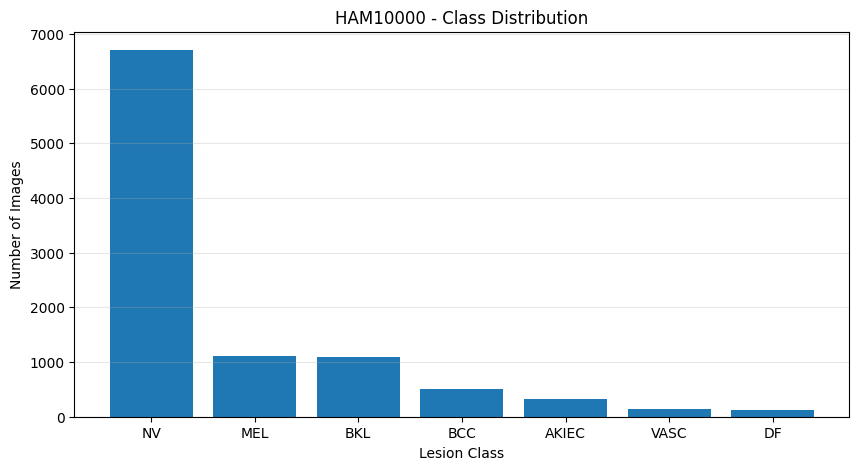

In [3]:
plt.figure(figsize=(10, 5))

plt.bar(
    class_summary.index,
    class_summary["Count"]
)

plt.title("HAM10000 - Class Distribution")
plt.xlabel("Lesion Class")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)

plt.show()

er sınıftan 3 rastgele görüntü 

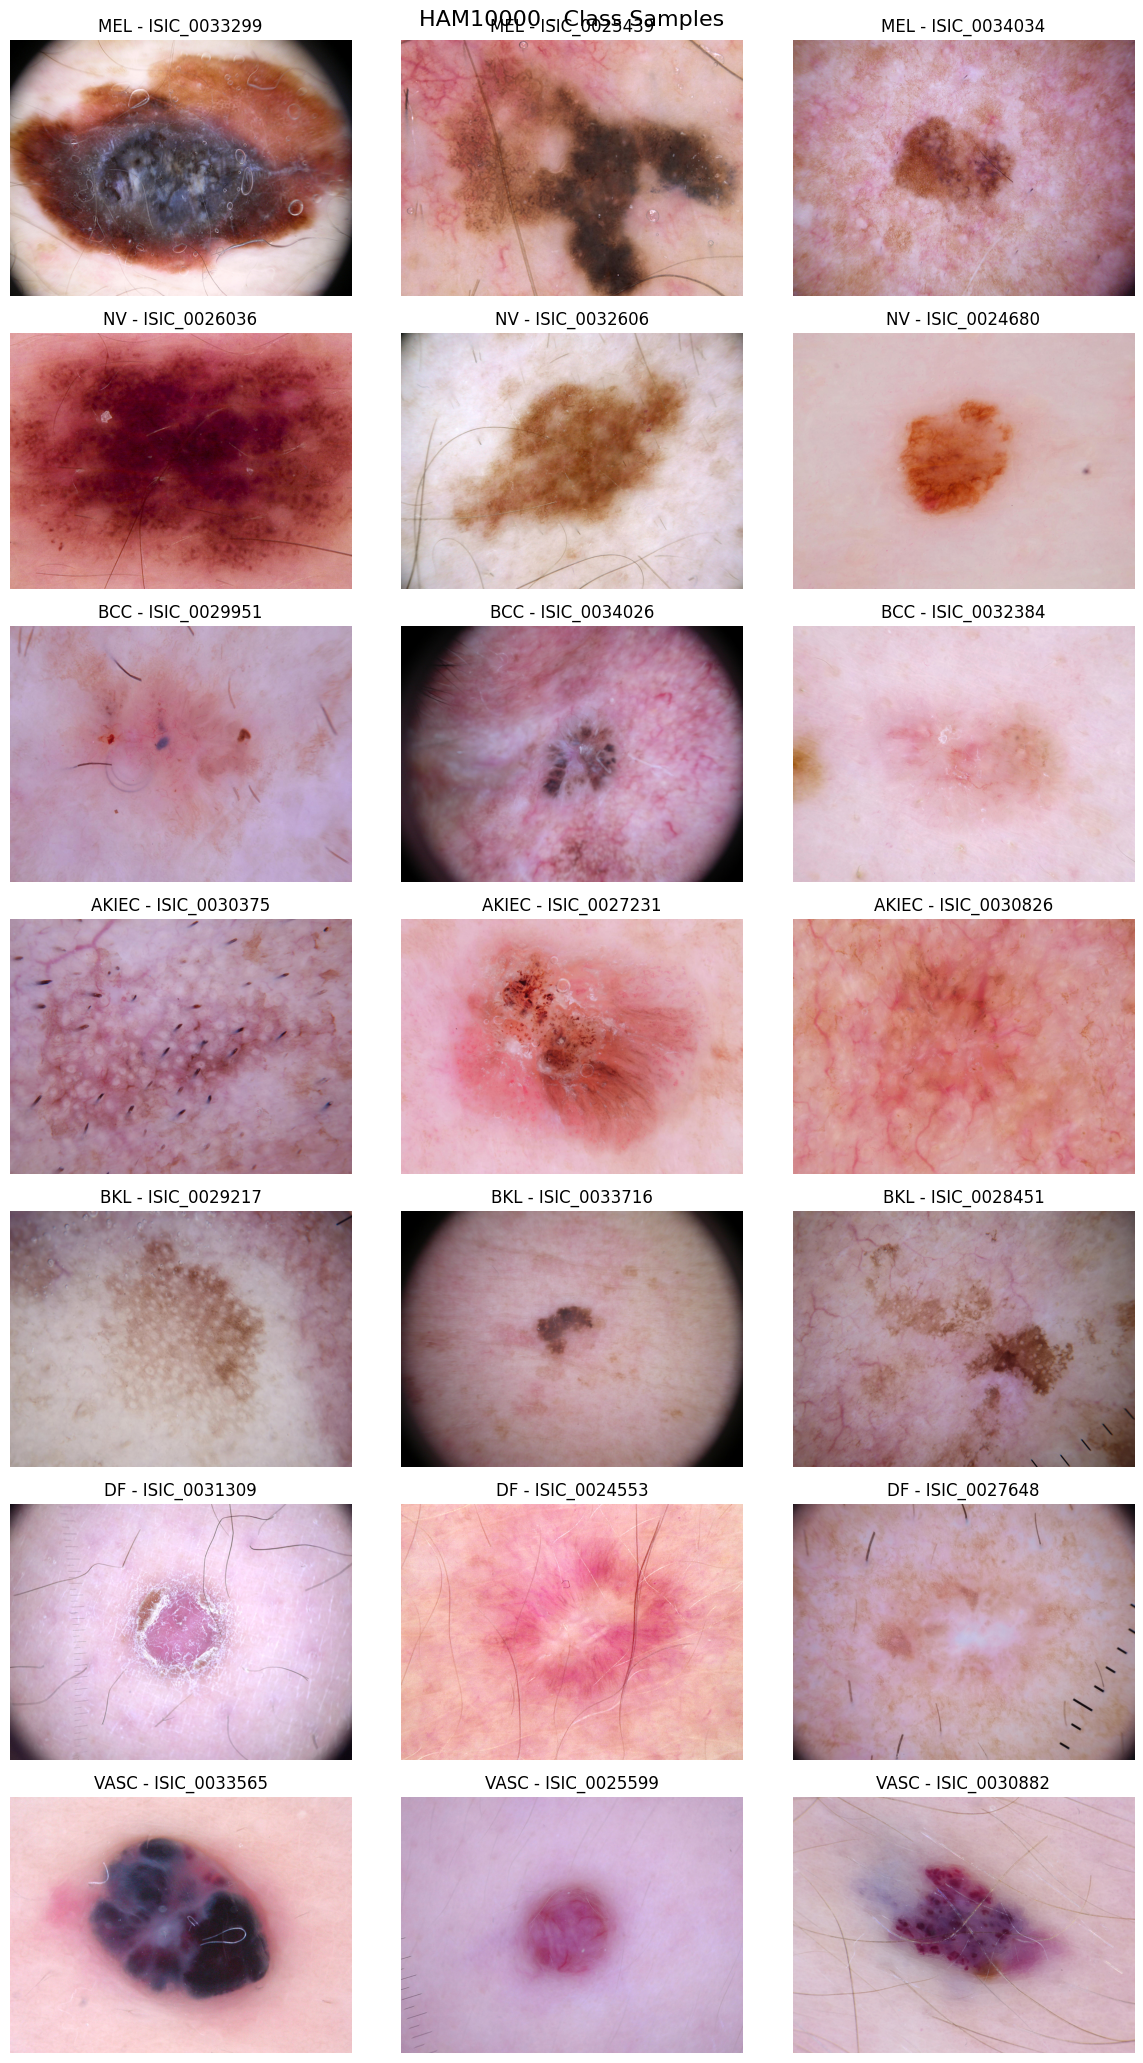

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from src.config import CLASSES
from src.preprocessing import read_image
'''def read_image(path):
    img = cv2.imdecode(
        np.fromfile(str(path), dtype=np.uint8),
        cv2.IMREAD_COLOR
    )
    return img'''

fig, axes = plt.subplots(
    nrows=7,
    ncols=3,
    figsize=(12, 21)
)

for i, cls in enumerate(CLASSES):

    samples = df[df["label"] == cls].sample(
        n=3,
        random_state=42
    )

    for j, (_, row) in enumerate(samples.iterrows()):

        img = read_image(row["image_path"])

        if img is None:
            raise ValueError(
                f"Görüntü okunamadı: {row['image_path']}"
            )

        img_rgb = cv2.cvtColor(
            img, cv2.COLOR_BGR2RGB
        )

        axes[i, j].imshow(img_rgb)
        axes[i, j].set_title(
            f"{cls} - {row['image']}"
        )
        axes[i, j].axis("off")

plt.suptitle(
    "HAM10000 - Class Samples",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [5]:


image_sizes = []
errors = []

for _, row in df.iterrows():
    try:
        image = read_image(row["image_path"])

        image_sizes.append({
            "image": row["image"],
            "height": image.shape[0],
            "width": image.shape[1],
            "channels": image.shape[2]
        })

    except Exception as e:
        errors.append((row["image"], str(e)))

sizes_df = pd.DataFrame(image_sizes)

print("Kontrol edilen görüntü:", len(sizes_df))
print("Hatalı görüntü:", len(errors))

print("\nFarklı görüntü boyutları:")
display(
    sizes_df.groupby(
        ["height", "width", "channels"]
    ).size().reset_index(name="count")
    .sort_values("count", ascending=False)
)

print("\nTüm görüntüler 450x600x3 mü?")
print(
    (
        (sizes_df["height"] == 450) &
        (sizes_df["width"] == 600) &
        (sizes_df["channels"] == 3)
    ).all()
)


Kontrol edilen görüntü: 10015
Hatalı görüntü: 0

Farklı görüntü boyutları:


,height,width,channels,count
0,450,600,3,10015



Tüm görüntüler 450x600x3 mü?
True


In [6]:
import winsound

winsound.Beep(300, 3000)
print("Ses testi tamamlandı.")

Ses testi tamamlandı.
